**GitHub repository:** https://github.com/Enne08/ai-employment-analysis.git



# AI, Data Science and Software Development Employment in the USA (May 2023)

This notebook explores the U.S. Bureau of Labor Statistics (BLS) **Occupational Employment and Wage Statistics (OEWS)** data for May 2023, focusing on jobs involving AI, data science and software development.

**Data source:** https://www.bls.gov/oes/tables.htm ("All data", May 2023)

**Contents**
1. Setup and data loading
2. Data inspection
3. Data cleaning
4. Selecting AI-related occupations
5. Visualisations *(to follow)*
6. Challenge: trends over time *(to follow)*
7. Conclusions *(to follow)*

## 1. Setup and data loading

I use **pandas** for data handling and **matplotlib** and **seaborn** for the charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

The raw file is large (about 80 MB, more than 400,000 rows), so it is stored in a `data/` folder that is **not** uploaded to GitHub. To run this notebook, download `all_data_M_2023.xlsx` from the BLS page above and place it in `data/`.

Loading takes a minute or two.

In [2]:
DATA_PATH = "data/all_data_M_2023.xlsx"

raw = pd.read_excel(DATA_PATH)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,O_GROUP,TOT_EMP,EMP_PRSE,JOBS_1000,LOC_QUOTIENT,PCT_TOTAL,PCT_RPT,H_MEAN,A_MEAN,MEAN_PRSE,H_PCT10,H_PCT25,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,total,151853870,0,NaN,NaN,NaN,NaN,31.48,65470,0.3,13.97,17.14,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,major,10495770,0.4,NaN,NaN,NaN,NaN,66.23,137750,0.5,26.23,37.66,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,minor,3751510,0.4,NaN,NaN,NaN,NaN,65.43,136100,0.9,22.31,31.81,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,broad,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,detailed,211230,1.4,NaN,NaN,NaN,NaN,124.47,258900,0.7,38.46,62.9,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## 2. Data inspection

First I check which columns are available and how the data is organised.

In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413327 entries, 0 to 413326
Data columns (total 32 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   AREA          413327 non-null  int64 
 1   AREA_TITLE    413327 non-null  object
 2   AREA_TYPE     413327 non-null  int64 
 3   PRIM_STATE    413327 non-null  object
 4   NAICS         413327 non-null  object
 5   NAICS_TITLE   413327 non-null  object
 6   I_GROUP       413327 non-null  object
 7   OWN_CODE      413327 non-null  int64 
 8   OCC_CODE      413327 non-null  object
 9   OCC_TITLE     413327 non-null  object
 10  O_GROUP       413327 non-null  object
 11  TOT_EMP       413327 non-null  object
 12  EMP_PRSE      413327 non-null  object
 13  JOBS_1000     235826 non-null  object
 14  LOC_QUOTIENT  235826 non-null  object
 15  PCT_TOTAL     170470 non-null  object
 16  PCT_RPT       170470 non-null  object
 17  H_MEAN        413327 non-null  object
 18  A_MEAN        413327 non

Key columns (from the BLS file layout):

| Column | Meaning |
|---|---|
| `AREA_TYPE` | 1 = U.S. national, 2 = state, 3 = territory, 4 = metropolitan area, 6 = non-metropolitan area |
| `PRIM_STATE` | State abbreviation |
| `I_GROUP` | Industry level: `cross-industry` means all industries combined |
| `NAICS_TITLE` | Industry name |
| `OCC_CODE` / `OCC_TITLE` | Occupation code and name |
| `O_GROUP` | Occupation level: `detailed`, `broad`, `minor`, `major`, `total` |
| `TOT_EMP` | Total employment |
| `A_MEAN`, `A_MEDIAN` | Mean and median annual wage |
| `A_PCT10` … `A_PCT90` | Annual wage percentiles |
| `LOC_QUOTIENT` | How concentrated the job is in an area compared with the U.S. average (1 = average) |

The file mixes several levels of detail. The same occupation appears once for the whole U.S., once per state, once per industry and so on. I have to filter carefully so that I don't double-count.

In [4]:
print("Area types:\n", raw["AREA_TYPE"].value_counts().sort_index(), "\n")
print("Industry groups:\n", raw["I_GROUP"].value_counts(), "\n")
print("Occupation groups:\n", raw["O_GROUP"].value_counts())

Area types:
 AREA_TYPE
1    177501
2     36643
3      1033
4    149591
6     48559
Name: count, dtype: int64 

Industry groups:
 I_GROUP
cross-industry               237229
4-digit                       83350
3-digit                       39097
sector                        16376
5-digit                       15518
4-digit, ownership             9856
cross-industry, ownership      5628
3-digit, ownership             4561
6-digit                        1712
Name: count, dtype: int64 

Occupation groups:
 O_GROUP
detailed    306185
broad        62131
minor        23374
major        20601
total         1036
Name: count, dtype: int64


## 3. Data cleaning

The numeric columns load as text because the BLS uses special symbols:

- `*` means the figure is not available
- `**` means employment could not be estimated
- `#` means the wage is at or above the top published value ($239,200 per year or $115 per hour)
- `~` means the figure is less than 0.5%

I convert these columns to numbers. Symbols become `NaN` (missing). For `#` I use the cap value of $239,200, because the real wage is *at least* that much. Dropping those rows would hide the highest earners.

In [5]:
df = raw.copy()

numeric_cols = ["TOT_EMP", "EMP_PRSE", "JOBS_1000", "LOC_QUOTIENT", "PCT_TOTAL",
                "H_MEAN", "A_MEAN", "H_MEDIAN", "A_MEDIAN",
                "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

ANNUAL_CAP = 239200
annual_wage_cols = ["A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

for col in numeric_cols:
    s = df[col].astype(str).str.strip()
    if col in annual_wage_cols:
        s = s.replace("#", str(ANNUAL_CAP))
    df[col] = pd.to_numeric(s.str.replace(",", ""), errors="coerce")

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
TOT_EMP,401729.0,12758.953075,360803.186348,30.000,100.000,320.00,1530.000,1.518539e+08
EMP_PRSE,401729.0,11.489593,10.038481,0.000,4.200,8.50,15.800,4.990000e+01
JOBS_1000,232193.0,7.384989,51.779168,0.002,0.413,1.05,2.961,1.000000e+03
LOC_QUOTIENT,232193.0,1.367247,2.735332,0.020,0.680,0.98,1.400,3.498200e+02
PCT_TOTAL,162584.0,1.346167,6.681308,0.000,0.020,0.11,0.550,1.000000e+02
H_MEAN,392363.0,32.475558,18.517677,8.050,20.610,27.19,38.740,3.533800e+02
A_MEAN,408244.0,68109.229603,38660.519950,16750.000,43210.000,57340.00,81430.000,1.805790e+06
H_MEDIAN,390268.0,29.804504,14.968021,7.250,19.100,25.10,36.430,1.149600e+02
A_MEDIAN,408244.0,63460.996610,33782.605405,15080.000,40160.000,53430.00,76970.000,2.392000e+05
A_PCT10,408244.0,42905.108367,20248.761249,15080.000,30350.000,37440.00,49250.000,2.392000e+05


## 4. Selecting AI-related occupations

The BLS has no single "AI" occupation code, so I chose the occupations that most closely match work in **AI, data science and software development**:

| Code | Occupation | Why it is included |
|---|---|---|
| 15-2051 | Data Scientists | Build machine-learning and predictive models; the core "AI" job |
| 15-1221 | Computer and Information Research Scientists | Research new computing methods, including AI and machine-learning algorithms |
| 15-1252 | Software Developers | Build the applications and systems that AI is deployed in |
| 15-1253 | Software Quality Assurance Analysts and Testers | Test software, including AI-powered products |
| 15-1211 | Computer Systems Analysts | Design systems and decide where technology such as AI fits into an organisation |
| 15-2031 | Operations Research Analysts | Use optimisation and statistical modelling, closely related to data science |

**Limitation:** these categories also include people who don't work on AI at all, especially among Software Developers. The data shows employment in AI-*related* fields, not AI jobs exactly.

In [6]:
AI_OCCUPATIONS = {
    "15-2051": "Data Scientists",
    "15-1221": "Computer & Info Research Scientists",
    "15-1252": "Software Developers",
    "15-1253": "Software QA Analysts & Testers",
    "15-1211": "Computer Systems Analysts",
    "15-2031": "Operations Research Analysts",
}

ai = df[df["OCC_CODE"].isin(AI_OCCUPATIONS)].copy()
ai["SHORT_TITLE"] = ai["OCC_CODE"].map(AI_OCCUPATIONS)
print("AI-related rows:", len(ai))

AI-related rows: 3681


Next I split the data into three tables, one for each level of detail I will chart:

- **`national`**: U.S. totals, all industries combined (one row per occupation)
- **`states`**: each of the 50 states plus DC, all industries combined
- **`industries`**: U.S. totals broken down by industry sector

In [7]:
cross = ai["I_GROUP"] == "cross-industry"

national = ai[(ai["AREA_TYPE"] == 1) & cross].sort_values("TOT_EMP", ascending=False)
states = ai[(ai["AREA_TYPE"] == 2) & cross]
industries = ai[(ai["AREA_TYPE"] == 1) & (ai["I_GROUP"] == "sector")]

print("National rows:", len(national))
print("State rows:", len(states), "| states per occupation:", states.groupby("OCC_CODE").size().unique())
print("Industry rows:", len(industries))

national[["OCC_CODE", "SHORT_TITLE", "TOT_EMP", "A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT90"]]

National rows: 6
State rows: 292 | states per occupation: [50 42 51 49]
Industry rows: 107


,OCC_CODE,SHORT_TITLE,TOT_EMP,A_MEAN,A_MEDIAN,A_PCT10,A_PCT90
149,15-1252,Software Developers,1656880.0,138110.0,132270.0,77020.0,208620.0
135,15-1211,Computer Systems Analysts,498810.0,110800.0,103800.0,63230.0,165700.0
150,15-1253,Software QA Analysts & Testers,203040.0,108460.0,101800.0,58740.0,164520.0
165,15-2051,Data Scientists,192710.0,119040.0,108020.0,61070.0,184090.0
161,15-2031,Operations Research Analysts,117880.0,95600.0,83640.0,52930.0,148920.0
138,15-1221,Computer & Info Research Scientists,35210.0,157160.0,145080.0,81450.0,233110.0


Not every occupation has 51 state rows. The BLS hides estimates when too few people are employed for a reliable figure (for example, Computer & Information Research Scientists appear in only 42 states). I need to remember this when comparing states.

A quick check of the totals before charting:

In [8]:
all_jobs = df.loc[(df["AREA_TYPE"] == 1) & (df["OCC_CODE"] == "00-0000"), "TOT_EMP"].iloc[0]
all_mean_wage = df.loc[(df["AREA_TYPE"] == 1) & (df["OCC_CODE"] == "00-0000"), "A_MEAN"].iloc[0]
ai_total = national["TOT_EMP"].sum()

print(f"Total U.S. employment:            {all_jobs:,.0f}")
print(f"AI-related employment:            {ai_total:,.0f}")
print(f"Share of all U.S. jobs:           {ai_total / all_jobs:.2%}")
print(f"Mean wage, all occupations:       ${all_mean_wage:,.0f}")
print(f"Mean wage range, AI-related jobs: ${national['A_MEAN'].min():,.0f} to ${national['A_MEAN'].max():,.0f}")

Total U.S. employment:            151,853,870
AI-related employment:            2,704,530
Share of all U.S. jobs:           1.78%
Mean wage, all occupations:       $65,470
Mean wage range, AI-related jobs: $95,600 to $157,160


Finally I save the three small tables as CSV files. They are only a few hundred KB, so they **can** be uploaded to GitHub, and the visualisation sections can load them quickly without re-reading the large Excel file.

In [10]:
import os
os.makedirs("data/processed", exist_ok=True)

keep = ["AREA_TITLE", "PRIM_STATE", "NAICS_TITLE", "OCC_CODE", "OCC_TITLE", "SHORT_TITLE",
        "TOT_EMP", "JOBS_1000", "LOC_QUOTIENT", "A_MEAN", "A_MEDIAN",
        "A_PCT10", "A_PCT25", "A_PCT75", "A_PCT90"]

national[keep].to_csv("data/processed/ai_national_2023.csv", index=False)
states[keep].to_csv("data/processed/ai_states_2023.csv", index=False)
industries[keep].to_csv("data/processed/ai_industries_2023.csv", index=False)
print("Saved processed files to data/processed/")

Saved processed files to data/processed/


## 5. Visualisations

To make this section quick to run, I load the small processed CSV files saved in section 4 instead of the large Excel file.

In [2]:
national = pd.read_csv("data/processed/ai_national_2023.csv")
states = pd.read_csv("data/processed/ai_states_2023.csv")
industries = pd.read_csv("data/processed/ai_industries_2023.csv")

national = national.sort_values("TOT_EMP", ascending=False)
colours = dict(zip(national["SHORT_TITLE"], sns.color_palette("Set2", len(national))))
print("Loaded:", len(national), "occupations,", len(states), "state rows,", len(industries), "industry rows")

Loaded: 6 occupations, 292 state rows, 107 industry rows


### Visualisation 1: Employment by occupation (horizontal bar chart)

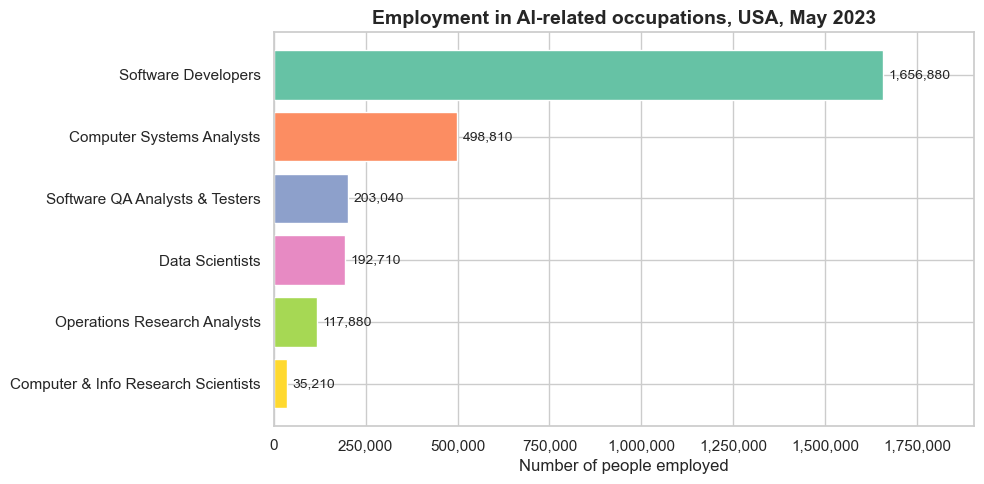

In [3]:
import matplotlib.ticker as mticker

data = national.sort_values("TOT_EMP")

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(data["SHORT_TITLE"], data["TOT_EMP"],
               color=[colours[t] for t in data["SHORT_TITLE"]])

for bar in bars:
    value = bar.get_width()
    ax.text(value + 15000, bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}", va="center", fontsize=10)

ax.set_title("Employment in AI-related occupations, USA, May 2023", fontsize=14, weight="bold")
ax.set_xlabel("Number of people employed")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, data["TOT_EMP"].max() * 1.15)
plt.tight_layout()
plt.show()

**Objective:** Comparison. To compare how many people work in each AI-related occupation and see which roles make up most of the workforce.

**Why this chart type:** The data is one categorical variable (occupation) and one numerical variable (employment). A bar chart is the clearest way to compare amounts across categories, because the eye compares bar lengths easily. I used horizontal bars because the occupation names are long and stay readable on the y-axis. Sorting the bars from largest to smallest, and labelling each with its exact value, makes the ranking obvious at a glance.

**What I learned:**
- Software Developers dominate, with about **1.66 million** jobs, more than three times the next occupation (Computer Systems Analysts, about 499,000).
- Data Scientists, the job most directly linked to AI, employ about **193,000** people. That is only about one-ninth the number of Software Developers.
- Computer & Information Research Scientists, who carry out most AI research, are the smallest group at only **35,210** people. Cutting-edge AI work is done by a very small, specialised workforce.
- In total, these six occupations employ about **2.7 million** people, roughly **1.8%** of all U.S. jobs.